图像阈值
ret,dst=cv2.threshold(src,thresh,maxval,type)
src：输入图，只能输入单通道图像，通常来说为灰度图
dst：输出图
thresh：阈值
maxval：当像素值超过了阈值（或者小于喻主席，根据type来决定），所赋予的值
type：二值化操作的类型，包含以下5中类型：
    cv2.THRESH_BINARY：超过阈值部分取maxval(最大值)，否则取0
    cv2.THRESH_BINARY_INV： cv2.THRESH_BINARY的反转
    cv2.THRESH_TRUNC：大于阈值的设为阈值，否则不变
    cv2.THRESH_TOZERO：大于阈值的部分不改变，否则设为0
    cv2.THRESH_TOZERO_INV： cv2.THRESH_TOZERO的反转

In [5]:
%matplotlib inline
%run basic_setup.py


img      : (148, 254, 3) uint8
img_gray : (148, 254) uint8


<Figure size 640x480 with 0 Axes>

In [6]:
# 五种阈值类型对比；threshold 返回的是 (retval, dst) 两个值
ret, thresh1 = cv2.threshold(img_gray, 128, 255, cv2.THRESH_BINARY)
ret, thresh2 = cv2.threshold(img_gray, 128, 255, cv2.THRESH_BINARY_INV)
ret, thresh3 = cv2.threshold(img_gray, 128, 255, cv2.THRESH_TRUNC)
ret, thresh4 = cv2.threshold(img_gray, 128, 255, cv2.THRESH_TOZERO)
ret, thresh5 = cv2.threshold(img_gray, 128, 255, cv2.THRESH_TOZERO_INV)

print("使用的阈值 ret =", ret)
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img_gray, thresh1, thresh2, thresh3, thresh4, thresh5]


使用的阈值 ret = 128.0


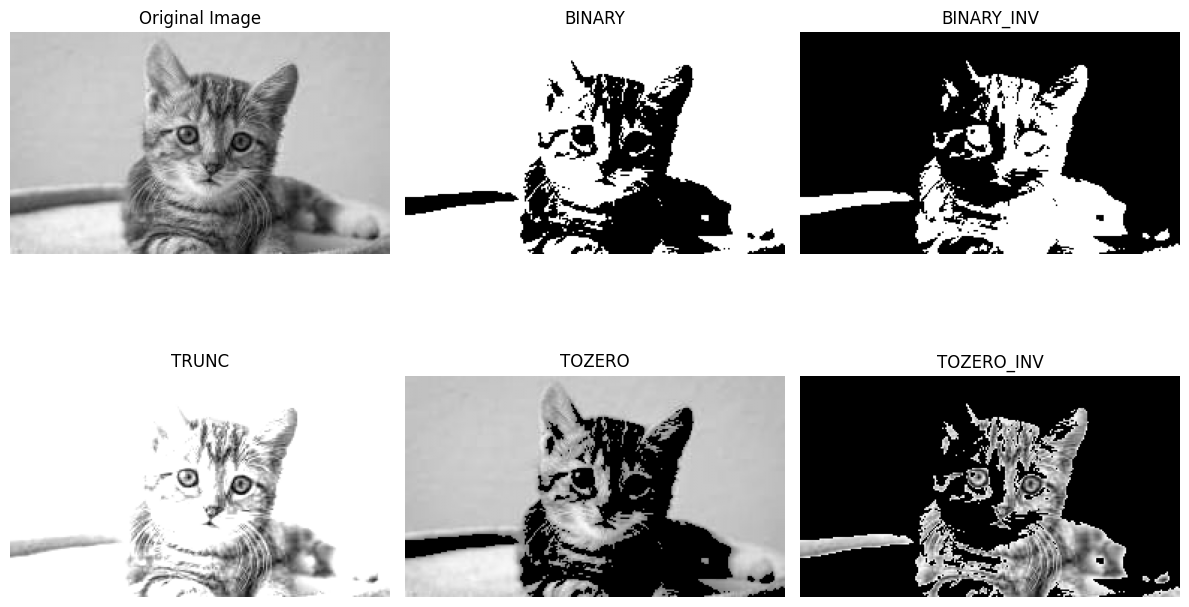

In [7]:
plt.figure(figsize=(12, 8))
for i in range(6):                      #循环6次，依次画6张图
    plt.subplot(2, 3, i + 1)            #布局为2行3列，选中第i+1个子图位置
    plt.imshow(images[i], cmap='gray')  #显示第i张图片，用灰度配色
    plt.title(titles[i])                #给当前子图设置标题（标题存在 titles 列表里）
    plt.axis('off')                     #关掉坐标轴、刻度
plt.tight_layout()                      #自动调整子图间距，防止标题互相重叠挤在一起
plt.show()


图像平滑

In [ ]:
img = cv2.imread('lenaNoise.png')   
cv2.imshow('img',img)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [ ]:
#均值滤波
#简单的平均卷积操作
blur = cv2.blur(img,(3,3))
cv2.imshow('blur',blur)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [10]:
#方框滤波
#基本和均值一样，可选择归一化
box=cv2.boxFilter(img,-1,(3,3),normalize=True)#-1和原通道数一致
cv2.imshow('box',box)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [11]:
#方框滤波,容易越界(直接取到225)
box=cv2.boxFilter(img,-1,(3,3),normalize=False)#-1和原通道数一致
cv2.imshow('box',box)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [ ]:
#高斯滤波,离得进的关系越紧密
#高斯模糊的卷积核里的数值满足高斯分布，更重视中间的
aussian=cv2.GaussianBlur(img,(3,3),1)#1：X方向高斯标准差σ；Y方向不写默认和X一样
cv2.imshow('aussian',aussian)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [20]:
#中值滤波，从小到大排序取中间
#相当于用中值替代
median=cv2.medianBlur(img,5)
cv2.imshow('blur',blur)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [ ]:
#展示所有
res=np.hstack((blur,aussian,median))#5：核大小，必须是奇数，这里代表5×5 的窗口
cv2.imshow('meidan vs average',res)
cv2.waitKey(1000)
cv2.destroyAllWindows()